# Source code

/home/sukhdev-singh/tf_env/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 32)     │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     3,212,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,274,634 (12.49 MB)

 Trainable params: 3,274,634 (12.49 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 66s 136ms/step - accuracy: 0.9402 - loss: 0.1881 - val_accuracy: 0.9872 - val_loss: 0.0435
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 57s 136ms/step - accuracy: 0.9810 - loss: 0.0616 - val_accuracy: 0.9882 - val_loss: 0.0406
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 137ms/step - accuracy: 0.9856 - loss: 0.0451 - val_accuracy: 0.9907 - val_loss: 0.0333
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 137ms/step - accuracy: 0.9877 - loss: 0.0387 - val_accuracy: 0.9915 - val_loss: 0.0292
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 137ms/step - accuracy: 0.9903 - loss: 0.0309 - val_accuracy: 0.9925 - val_loss: 0.0269
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 137ms/step - accuracy: 0.9908 - loss: 0.0274 - val_accuracy: 0.9925 - val_loss: 0.0276
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 138ms/step - accuracy: 0.9920 - loss: 0.0239 - val_accuracy: 0.9923 - val_loss: 0.0235
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 138ms/step - accuracy: 0.9928 - loss: 0

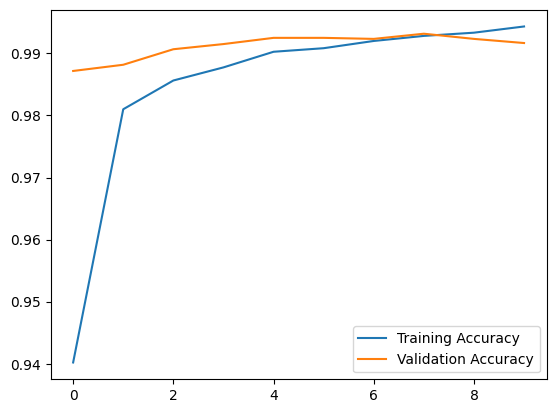

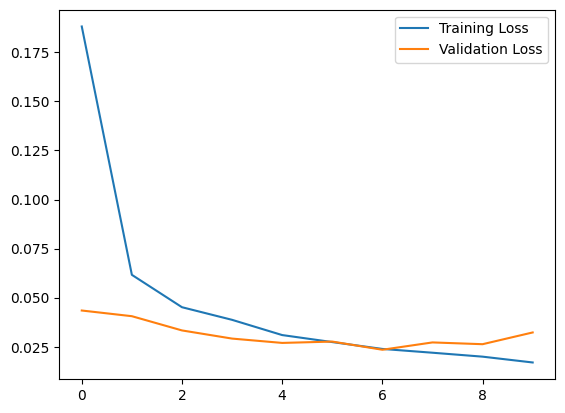

In [5]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Load MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Reshape
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# CNN Model
model = tf.keras.Sequential([

    # First Convolution Layer
    tf.keras.layers.Conv2D(
        filters=32,
        kernel_size=(5,5),
        strides=(1,1),
        padding="same",
        activation="relu",
        input_shape=(28,28,1)
    ),

    # Max Pool Layer
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),

    # Dropout
    tf.keras.layers.Dropout(0.25),

    # Second Convolution Layer
    tf.keras.layers.Conv2D(
        filters=64,
        kernel_size=(5,5),
        padding="same",
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),

    tf.keras.layers.Dropout(0.25),

    # Flatten
    tf.keras.layers.Flatten(),

    # Fully Connected Layer
    tf.keras.layers.Dense(1024, activation="relu"),

    tf.keras.layers.Dropout(0.5),

    # Output Layer
    tf.keras.layers.Dense(10, activation="softmax")
])

# Compile
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Model Summary
model.summary()

# Train
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# Evaluate
loss, accuracy = model.evaluate(x_test, y_test)

print("\nTest Accuracy =", accuracy)

# Accuracy Graph
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.legend()
plt.show()

# Loss Graph
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.show()

# First convolutional layer

Input Shape : (1, 28, 28, 1)
Output Shape: (1, 28, 28, 32)


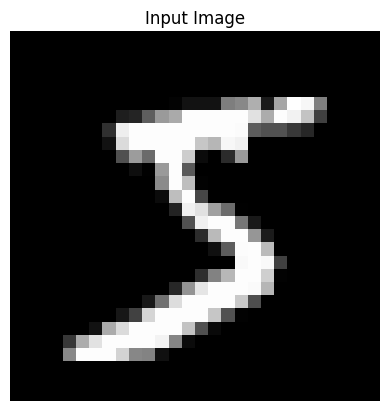

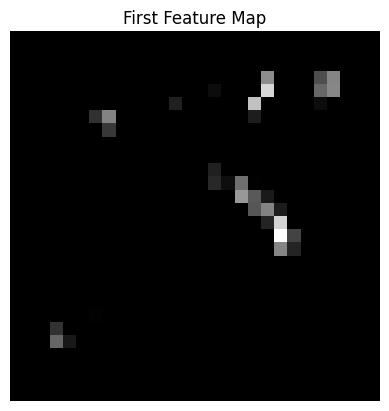

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Add channel dimension
x_train = x_train[..., tf.newaxis]
x_test = x_test[..., tf.newaxis]

# First Convolution Layer
conv1 = tf.keras.layers.Conv2D(
    filters=32,
    kernel_size=(4,3),
    strides=(1,1),
    padding="same",
    activation="relu"
)

# Apply convolution
output = conv1(x_train[:1])

print("Input Shape :", x_train[:1].shape)
print("Output Shape:", output.shape)

# Display Input Image
plt.imshow(x_train[0].squeeze(), cmap="gray")
plt.title("Input Image")
plt.axis("off")
plt.show()

# Display First Feature Map
plt.imshow(output[0, :, :, 0], cmap="gray")
plt.title("First Feature Map")
plt.axis("off")
plt.show()

# Launching the session

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 61s 143ms/step - accuracy: 0.9406 - loss: 0.1889 - val_accuracy: 0.9833 - val_loss: 0.0550
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 57s 136ms/step - accuracy: 0.9814 - loss: 0.0588 - val_accuracy: 0.9903 - val_loss: 0.0328
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 57s 136ms/step - accuracy: 0.9858 - loss: 0.0452 - val_accuracy: 0.9888 - val_loss: 0.0377
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 136ms/step - accuracy: 0.9884 - loss: 0.0355 - val_accuracy: 0.9918 - val_loss: 0.0295
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 137ms/step - accuracy: 0.9905 - loss: 0.0291 - val_accuracy: 0.9915 - val_loss: 0.0315
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 138ms/step - accuracy: 0.9918 - loss: 0.0260 - val_accuracy: 0.9935 - val_loss: 0.0265
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 138ms/step - accuracy: 0.9920 - loss: 0.0239 - val_accuracy: 0.9927 - val_loss: 0.0297
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 58s 138ms/step - accuracy: 0.9933 - loss: 0

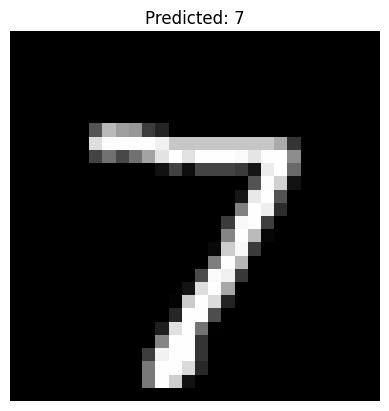

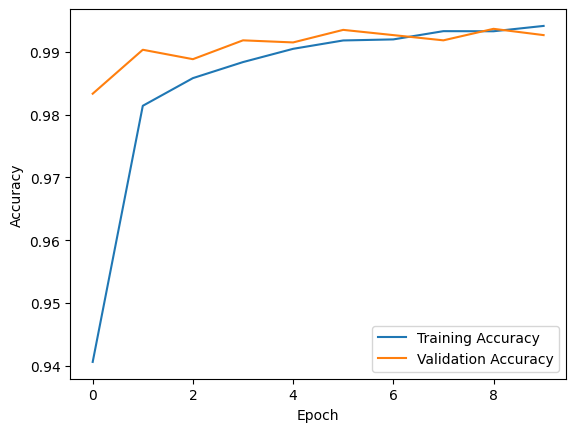

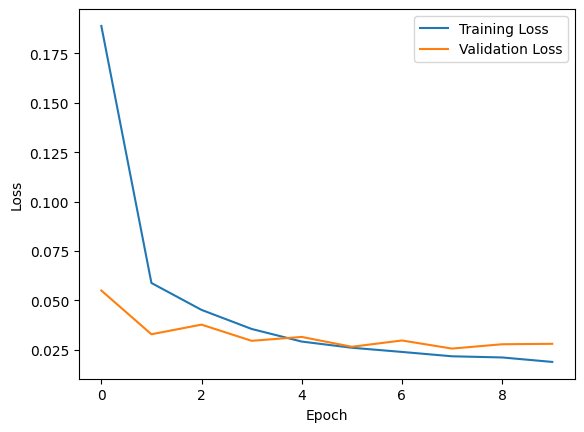

In [6]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.datasets import mnist

# Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize Images
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Reshape Images
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# One-Hot Encoding
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

# Parameters
learning_rate = 0.001
batch_size = 128
epochs = 10
dropout = 0.5

# Build CNN Model
model = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(
        32, (5,5),
        activation='relu',
        padding='same',
        input_shape=(28,28,1)
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(
        64, (5,5),
        activation='relu',
        padding='same'
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1024, activation='relu'),
    tf.keras.layers.Dropout(dropout),
    tf.keras.layers.Dense(10, activation='softmax')
])
# Compile Model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# Train Model
history = model.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.1,
    verbose=1
)

# Evaluate Model
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)

print("Testing Accuracy:", accuracy)

# Predict First Image
prediction = model.predict(x_test[:1])
print("Predicted Digit:", np.argmax(prediction))
print("Actual Digit:", np.argmax(y_test[0]))

# Display Image
import matplotlib.pyplot as plt

plt.imshow(x_test[0].reshape(28,28), cmap="gray")
plt.title("Predicted: {}".format(np.argmax(prediction)))
plt.axis("off")
plt.show()

# Plot Accuracy Graph
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Plot Loss Graph
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()